In [4]:
# ══════════════════════════════════════════════════════════════
# 0. IMPORTS
# ══════════════════════════════════════════════════════════════
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms, models
from lime import lime_image

# ══════════════════════════════════════════════════════════════
# 1. CONFIG — UBAH SESUAI KEBUTUHAN
# ══════════════════════════════════════════════════════════════
CFG = {
    "model_name":  "ResNet50",                       # "XceptionNet" / "EfficientNet-B0" / "ResNet50"
    "checkpoint":  "checkpoints/resnet50_best.pth",  # sesuaikan
    "image_path":  "test_images/fake/fake_9830.jpg",    # sesuaikan
    "random_seed": 42,
    "lime_num_samples": 1000,
}

# Konfigurasi per model (img_size & normalisasi)
MODEL_CONFIGS = {
    "XceptionNet": {
        "img_size":  299,
        "norm_mean": [0.5, 0.5, 0.5],
        "norm_std":  [0.5, 0.5, 0.5],
    },
    "EfficientNet-B0": {
        "img_size":  224,
        "norm_mean": [0.485, 0.456, 0.406],
        "norm_std":  [0.229, 0.224, 0.225],
    },
    "ResNet50": {
        "img_size":  224,
        "norm_mean": [0.485, 0.456, 0.406],
        "norm_std":  [0.229, 0.224, 0.225],
    },
}

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
np.random.seed(CFG["random_seed"])
torch.manual_seed(CFG["random_seed"])


# ══════════════════════════════════════════════════════════════
# 2. MODEL BUILDERS
# ══════════════════════════════════════════════════════════════

def build_xceptionnet() -> nn.Module:
    import timm
    base = timm.create_model("xception", pretrained=False, num_classes=0)

    class XceptionNet(nn.Module):
        def __init__(self, backbone, in_feat):
            super().__init__()
            self.backbone = backbone
            self.head = nn.Sequential(
                nn.Dropout(0.5), nn.Linear(in_feat, 256),
                nn.ReLU(inplace=False), nn.Dropout(0.3), nn.Linear(256, 2),
            )
            self.gradcam_target_layer = backbone.act4

        def forward(self, x):
            return self.head(self.backbone(x))

    return XceptionNet(base, base.num_features)


def build_efficientnet() -> nn.Module:
    base = models.efficientnet_b0(weights=None)

    class EfficientNetB0(nn.Module):
        def __init__(self, backbone):
            super().__init__()
            self.backbone = backbone.features
            self.pool     = nn.AdaptiveAvgPool2d(1)
            self.head     = nn.Sequential(
                nn.Dropout(0.5), nn.Linear(1280, 256),
                nn.ReLU(inplace=False), nn.Dropout(0.3), nn.Linear(256, 2),
            )
            self.gradcam_target_layer = backbone.features[-1]

        def forward(self, x):
            return self.head(self.pool(self.backbone(x)).flatten(1))

    return EfficientNetB0(base)


def build_resnet50() -> nn.Module:
    base = models.resnet50(weights=None)

    class ResNet50(nn.Module):
        def __init__(self, backbone):
            super().__init__()
            self.conv1   = backbone.conv1
            self.bn1     = backbone.bn1
            self.relu    = nn.ReLU(inplace=False)
            self.maxpool = backbone.maxpool
            self.layer1  = backbone.layer1
            self.layer2  = backbone.layer2
            self.layer3  = backbone.layer3
            self.layer4  = backbone.layer4
            self.avgpool = backbone.avgpool
            self.head    = nn.Sequential(
                nn.Dropout(0.5), nn.Linear(2048, 256),
                nn.ReLU(inplace=False), nn.Dropout(0.3), nn.Linear(256, 2),
            )
            self.gradcam_target_layer = backbone.layer4

        def forward(self, x):
            x = self.maxpool(self.relu(self.bn1(self.conv1(x))))
            x = self.layer4(self.layer3(self.layer2(self.layer1(x))))
            return self.head(torch.flatten(self.avgpool(x), 1))

    return ResNet50(base)


MODEL_BUILDERS = {
    "XceptionNet":     build_xceptionnet,
    "EfficientNet-B0": build_efficientnet,
    "ResNet50":        build_resnet50,
}


def load_model(model_name: str, checkpoint_path: str) -> nn.Module:
    ckpt_path = Path(checkpoint_path)
    if not ckpt_path.exists():
        raise FileNotFoundError(f"Checkpoint tidak ditemukan: {ckpt_path}")

    model = MODEL_BUILDERS[model_name]()
    ckpt  = torch.load(ckpt_path, map_location="cpu", weights_only=False)
    model.load_state_dict(ckpt["model_state"])
    model = model.to(DEVICE).eval()
    print(f"✓ {model_name} dimuat | epoch={ckpt.get('epoch','?')} | val_auc={ckpt.get('val_auc',0):.4f}")
    return model


# ══════════════════════════════════════════════════════════════
# 3. PREPROCESSING
# ══════════════════════════════════════════════════════════════

def get_transform(model_name: str) -> transforms.Compose:
    c = MODEL_CONFIGS[model_name]
    return transforms.Compose([
        transforms.ToPILImage(),
        transforms.Resize((c["img_size"], c["img_size"])),
        transforms.ToTensor(),
        transforms.Normalize(c["norm_mean"], c["norm_std"]),
    ])


def load_image(img_path: str, model_name: str):
    img_bgr = cv2.imread(img_path)
    if img_bgr is None:
        raise FileNotFoundError(f"Gambar tidak ditemukan / gagal dibaca: {img_path}")

    size    = MODEL_CONFIGS[model_name]["img_size"]
    img_rgb = cv2.resize(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB), (size, size))
    tensor  = get_transform(model_name)(img_rgb).unsqueeze(0).to(DEVICE)
    return img_rgb, tensor


# ══════════════════════════════════════════════════════════════
# 4. GRAD-CAM
# ══════════════════════════════════════════════════════════════

class GradCAM:
    def __init__(self, model: nn.Module):
        self.model  = model
        self._grads = None
        self._acts  = None
        self._hooks = [
            model.gradcam_target_layer.register_forward_hook(
                lambda m, i, o: setattr(self, "_acts", o.detach())
            ),
            model.gradcam_target_layer.register_full_backward_hook(
                lambda m, gi, go: setattr(self, "_grads", go[0].detach())
            ),
        ]

    def remove_hooks(self):
        for h in self._hooks:
            h.remove()

    def __call__(self, tensor: torch.Tensor, class_idx: int = None):
        self.model.zero_grad()
        out = self.model(tensor)
        probs = F.softmax(out, dim=1).detach().cpu().numpy()[0]

        if class_idx is None:
            class_idx = out.argmax(1).item()
        out[0, class_idx].backward()

        cam = (self._grads.mean(dim=[2, 3], keepdim=True) * self._acts).sum(1)
        cam = cam.clamp(min=0).squeeze().cpu().numpy()

        size = tensor.shape[-1]
        if cam.ndim == 0:
            return np.zeros((size, size), dtype=np.float32), class_idx, probs
        if cam.max() > cam.min():
            cam = (cam - cam.min()) / (cam.max() - cam.min())

        cam = cv2.resize(cam, (size, size)).astype(np.float32)
        return cam, class_idx, probs


# ══════════════════════════════════════════════════════════════
# 5. LIME
# ══════════════════════════════════════════════════════════════

def compute_lime(model: nn.Module, img_rgb: np.ndarray, model_name: str) -> np.ndarray:
    tf = get_transform(model_name)

    def predict_fn(images):
        batch = torch.stack([
            tf(img.astype(np.uint8)) for img in images
        ]).to(DEVICE)
        with torch.no_grad():
            return F.softmax(model(batch), dim=1).cpu().numpy()

    exp = lime_image.LimeImageExplainer(
        random_state=CFG["random_seed"]
    ).explain_instance(
        img_rgb, predict_fn,
        top_labels=2, hide_color=0,
        num_samples=CFG["lime_num_samples"],
        random_seed=CFG["random_seed"],
    )

    top_label = exp.top_labels[0]
    sal_map   = np.zeros(exp.segments.shape, dtype=np.float32)
    for seg_id, weight in exp.local_exp[top_label]:
        sal_map[exp.segments == seg_id] = weight

    if sal_map.max() > sal_map.min():
        sal_map = (sal_map - sal_map.min()) / (sal_map.max() - sal_map.min())

    return sal_map.astype(np.float32)


# ══════════════════════════════════════════════════════════════
# 6. PLOT
# ══════════════════════════════════════════════════════════════

def overlay_heatmap(img, hmap, cmap=cv2.COLORMAP_JET):
    h = cv2.cvtColor(
        cv2.applyColorMap((hmap * 255).astype(np.uint8), cmap),
        cv2.COLOR_BGR2RGB,
    )
    return (img * 0.5 + h * 0.5).astype(np.uint8)


def plot_single(img_rgb, gc_map, lime_map, pred_label, probs, model_name):
    label_name = "FAKE" if pred_label == 1 else "REAL"
    confidence = probs[pred_label] * 100

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(img_rgb)
    axes[0].set_title(f"Original\nPrediction: {label_name}")
    axes[0].axis("off")

    axes[1].imshow(overlay_heatmap(img_rgb, gc_map, cv2.COLORMAP_JET))
    axes[1].set_title("Grad-CAM")
    axes[1].axis("off")

    axes[2].imshow(overlay_heatmap(img_rgb, lime_map, cv2.COLORMAP_INFERNO))
    axes[2].set_title("LIME")
    axes[2].axis("off")

    plt.suptitle(f"{model_name} — XAI Visualization", fontsize=13)
    plt.tight_layout()
    plt.show()

Model      : ResNet50
Checkpoint : checkpoints/resnet50_best.pth
Image      : test_images/fake/fake_9830.jpg
Device     : cuda

✓ ResNet50 dimuat | epoch=18 | val_auc=0.9858


100%|██████████| 1000/1000 [00:06<00:00, 163.11it/s]


Prediction : FAKE
Probabilities: real=0.2812 | fake=0.7188


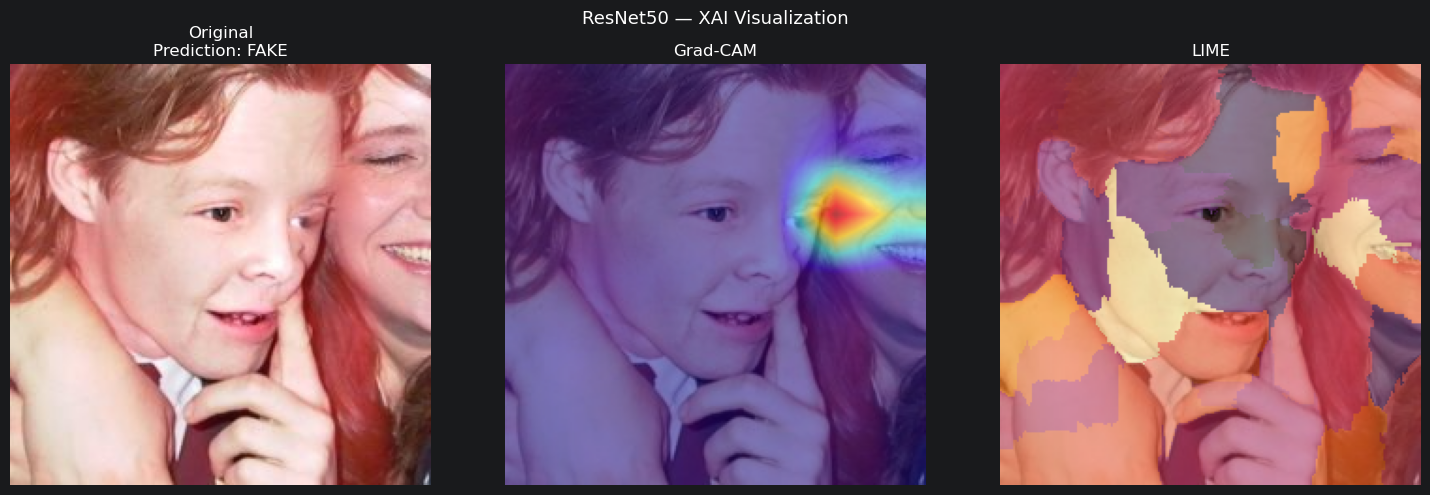

In [5]:

def main():
    model_name = CFG["model_name"]
    print(f"Model      : {model_name}")
    print(f"Checkpoint : {CFG['checkpoint']}")
    print(f"Image      : {CFG['image_path']}")
    print(f"Device     : {DEVICE}\n")

    # Load model & image
    model            = load_model(model_name, CFG["checkpoint"])
    img_rgb, tensor  = load_image(CFG["image_path"], model_name)

    # Grad-CAM
    gradcam = GradCAM(model)
    gc_map, pred_label, probs = gradcam(tensor)
    gradcam.remove_hooks()

    # LIME
    lime_map = compute_lime(model, img_rgb, model_name)

    print(f"Prediction : {'FAKE' if pred_label == 1 else 'REAL'}")
    print(f"Probabilities: real={probs[0]:.4f} | fake={probs[1]:.4f}")

    # Plot
    plot_single(img_rgb, gc_map, lime_map, pred_label, probs, model_name)

    return gc_map, lime_map, pred_label, probs


if __name__ == "__main__":
    main()
